In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

# 군집화(clustering)

군집화란 여러개의 데이터가 있을 때 `비슷한 데이터끼리 묶어주는 것`을 의미한다.

머신러닝의 학습 방법 크게 지도 학습(supervised learning), 비지도 학습(unsupervised learning)으로 나눌 수 있다.  
지도 학습이란 라벨링 된 데이터를 학습(문제와 정답)시키는 것을 의미하고, 비지도 학습 라벨링 되지 않는 데이터를 학습(문제만)시키는 것을 의미하며, 라벨링이란 학습 데이터에 정답(실제값, 관측값, 레이블, 클래스, 타겟)이 표시된 것을 의미한다.

비지도 학습 알고리즘은 정답이 없으므로 정확한 방향성이 일치하지 않더라도 알아서 학습이 가능한 알고리즘으로 데이터를 군집화하는 알고리즘이 비지도 학습에 속한다.
레이블 없이 피쳐 데이터만 활용해서 데이터를 학습시킨다. 지도 학습에서는 데이터를 분류하는 것을 classification라고 했지만, 비지도 학습에서는 데이터를 분류하는 것을 clustering이라고 한다.

# k평균 클러스터링(KMeans clustering)

k평균 클러스터링은 n개의 데이터를 k개의 클러스터로 나누는 기법이다. k평균 클러스터링은 각 데이터 포인트와 각 그룹의 평균(중심)간의 거리를 구한 후 가장 가까운 클러스터로 배정하는 방법이다.

k평균 클러스터링에서는 거리라는 개념이 사용되고 여기서는 유클리드 거리(euclidean distance)를 사용한다. 데이터 포인트 x와 데이터 포인트 y 사이의 유클리드 거리는 아래와 같은 공식을 사용한다.

$$d(x, y) = \sqrt {\sum_{i=1}^n (x_i - y_i)^2}$$

## k평균 클러스터링 알고리즘

① `그룹 평균 초기화`  
&nbsp;&nbsp;&nbsp;k평균 클러스터링 알고리즘의 첫 과정은 각 그룹의 평균을 초기화하는 것인데, 이때 사용하는 가장 기본적인 방법은 랜덤으로 평균(중심)을 설정하는 것이다.  
② `그룹 할당`  
&nbsp;&nbsp;&nbsp;각 데이터 포인트와 가장 가까운 그룹 평균에 해당되는 그룹에 할당한다. 각 데이터 포인트와 각 그룹의 평균까지의 거리를 계산해서 가장 가까운 그룹에 속하게 한다.  
③ `평균 업데이트`  
&nbsp;&nbsp;&nbsp;위 ② 단계를 거치면 모든 데이터 포인트가 어떤 그룹에 속하는지 알 수 있다. 그 후 각 그룹에 대한 새로운 평균값을 계산한다.  
④ `반복`  
&nbsp;&nbsp;&nbsp;② 단계에서 바뀌는 값이 없을 때 까지 ② ~ ③ 단계를 반복한다.

k평균 클러스터링은 사용하기 쉽다는 장점이 있지만 k평균 클러스터링에서는 가중치를 주지않아 클러스터간 데이터의 밀도 차이가 있을 경우 클러스터링이 잘되지 않는 단점이 있다. 그리고 k평균 클러스터링은 데이터들이 배치되는 모양을 고려하지 않으며, 초기 k값을 사용자가 지정해야 한다는 단점이 있다.

## k평균 클러스터링 알고리즘 동작 원리

무작위로 클러스터의 중심을 선택하고 중심에 가까운 데이터를 클러스터에 포함시키는 작업을 반복한 수 선택된 클러스터의 중심을 클러스터에 포함된 데이터의 중앙으로 이동하는 과정을 반복 수행해서 더 이상 클러스터의 중심 위치가 변하지 않을 때 까지 반복하는 것이 일반적인 방법이다.

군집화를 위한 무작위로 클러스터의 중심을 결정하는 방법은 임의의 데이터(노드)를 선택해서 클러스터의 중심으로 설정(파랑색)한다.  
그 이후에는 무작위로 선택된 클러스터의 중심에서 가장 거리가 먼 데이터(노랑색)를 선택해서 두 번째 클러스터의 중심으로 설정한다.  
다음 부터는 이미 선택된 클러스터의 중심들(파랑색, 노랑색)로부터 가장 멀리 떨어져있는 데이터(녹색)을 선택해서 클러스터의 중심으로 선택하는 작업을 반복한다.

<img src="Clustering1.png" width="1200" align="left" />

위와 같이 클러스터의 중심을 선택하는 작업을 했더니 3개의 클러스터가 존재한다고 가정하고 각각의 데이터를 선택해서 세 개의 클러스터 중심에서 가장 가까운 클러스터에 속하도록 만드는 작업을 반복해서 실행한다.

<img src="Clustering2.png" width="1200" align="left" />

위의 과정을 반복하면 아래 왼쪽의 그림과 같을 것이다.

<img src="Clustering3.png" width="1200" align="left" />

위의 왼쪽 그림과 같이 대략적으로 군집화가 완료되면 완벽한 군집화를 위해 클러스터 중심 위치를 위의 오른쪽 그림과 같이 군집화된 데이터들의 중심으로 이동시킨다.  
클러스터의 중심을 이동시키고 다시 모든 데이터에 대해서 어떤 클러스터의 중심에 가까운지 하나씩 검사해서 만약 특정 데이터가 다른 클러스터의 중심에 더 가깝다면 그 클러스터에 속하도록 설정하는 작업을 반복한다.

클러스터의 중심 위치가 더 이상 변경되지 않으면 군집화가 완료되는 것이다.

## k평균 클러스터링 알고리즘을 적용할 데이터를 읽어온다.

In [2]:
df = pd.read_csv('./data/cluster.csv')
print(df.shape)
df.head()

(30, 2)


,x,y
0,2,3
1,2,11
2,2,18
3,4,5
4,4,7


## k평균 클러스터링 적용 전 데이터 시각화

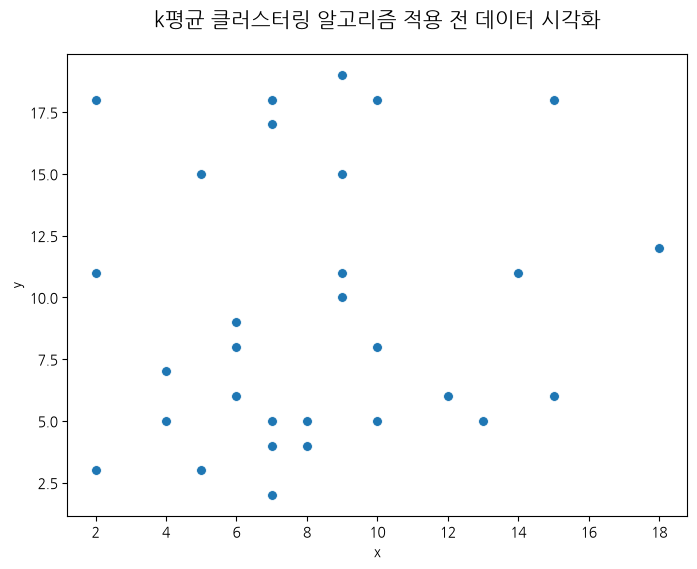

In [3]:
plt.figure(figsize=[8, 6])
sns.scatterplot(data=df, x='x', y='y', s=50)
plt.title('k평균 클러스터링 알고리즘 적용 전 데이터 시각화', pad=20, fontsize=15)
plt.show()

## k평균 클러스터링  모델을 만들고 학습 시킨다.

k평균 클러스터링 알고리즘을 사용하기 위해 KMeans를 import 한다.

In [4]:
from sklearn.cluster import KMeans

n_clusters에 군집화하려는 클러스터의 개수를 지정해서 k평균 클러스터링 모델을 만들고 군집화할 데이터를 넘겨서 학습시킨다.

In [5]:
model = KMeans(n_clusters=4)
model.fit(df.values)

KMeans(n_clusters=4)

## 각 클러스터의 중심과 데이터가 할당된 클러스터를 확인한다.

cluster_centers_ 속성으로 각 클러스터의 중심을 얻어올 수 있다.

In [6]:
print(model.cluster_centers_)

[[ 6.375 16.375]
 [ 5.8    4.4  ]
 [15.5   11.75 ]
 [ 9.375  7.75 ]]


labels_ 속성으로 각 데이터가 할당된 클러스터를 얻어올 수 있다.

In [7]:
print(model.labels_)

[1 0 0 1 1 1 0 1 3 3 1 1 1 0 0 1 1 3 3 0 0 3 3 0 3 3 2 2 2 2]


## 데이터프레임에 label이라는 파생 변수를 만들고 각 데이터가 할당된 클러스터를 넣어준다.

In [10]:
df['label'] = model.labels_
df.to_csv('./data/cluster_label.csv', index=False)
df.head()

,x,y,label
0,2,3,1
1,2,11,0
2,2,18,0
3,4,5,1
4,4,7,1


## k평균 클러스터링 적용 후 데이터 시각화

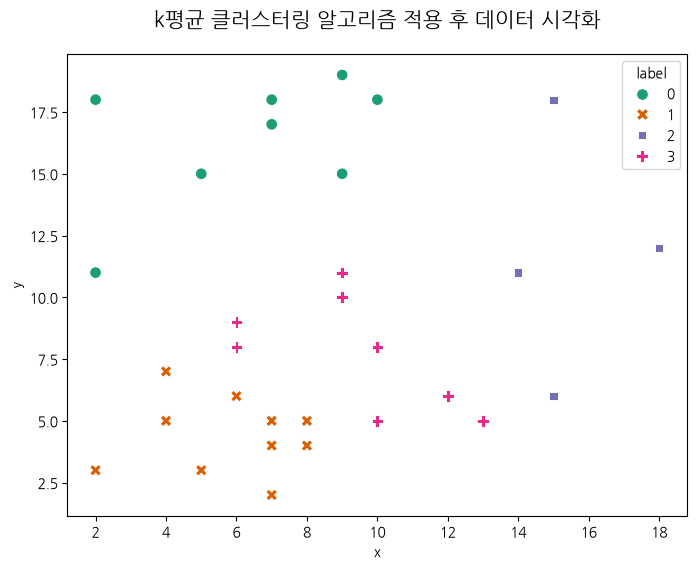

In [15]:
plt.figure(figsize=[8, 6])
sns.scatterplot(data=df, x='x', y='y', s=70, hue='label', palette='Dark2', style='label')
plt.title('k평균 클러스터링 알고리즘 적용 후 데이터 시각화', pad=20, fontsize=15)
plt.show()

<img src="palette.png" width="1200" align="left" />